### RANDOM FOREST- REGRESSOR

import libraries and load dataset, train test split

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df=pd.read_csv("teen_phone_addiction_dataset.csv")
y = df["Addiction_Level"]
X = df.drop(columns=["Addiction_Level", "ID", "Name", "Location"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

fill missing values, convert categorical to numerical


In [2]:
for column in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[column]):
        fill_value = X_train[column].median()
    else:
        modes = X_train[column].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    X_train[column] = X_train[column].fillna(fill_value)
    X_test[column] = X_test[column].fillna(fill_value)

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

Create and train the model


In [4]:
model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

model.fit(X_train, y_train);

Predict and evaluate

In [5]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

comparison = pd.DataFrame({
    "Actual Addiction_Level": y_test,
    "Predicted Addiction_Level": predictions
})

display(comparison.head(10))

MAE:  0.388
RMSE: 0.574
R²:   0.869


,Actual Addiction_Level,Predicted Addiction_Level
1801,10.0,9.884896
1190,10.0,9.907063
1817,10.0,9.940022
251,9.0,8.684269
2505,10.0,9.980339
1117,8.7,8.235434
1411,4.6,5.719503
2113,10.0,9.884322
408,10.0,9.457870
2579,10.0,9.993824


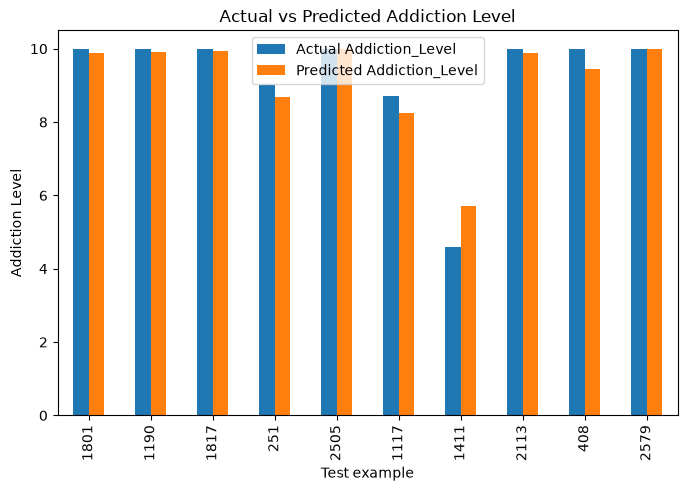

In [7]:
import matplotlib.pyplot as plt

comparison.head(10).plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Addiction Level")
plt.xlabel("Test example")
plt.ylabel("Addiction Level")
plt.show()